```
CISC7204 Suggested Exercise 08 — Practice 2
Exercise 8.04: Plotting the Movement of an Aircraft with a Custom Layer
```

**Student:** MC652428 LU ZIYI

**Library substitution (please read).** The tutorial is written for
**geoplotlib 0.3.2**. That library cannot be installed in this environment: its
`setup.py` relies on `use_2to3` (removed in setuptools 58; this machine has 83),
it is a Python-2 era package unsupported on Python 3.14, and `geoplotlib.show()`
requires an interactive OpenGL window that this environment cannot create.

Every geoplotlib layer used below is therefore reproduced with
**matplotlib + numpy + scipy**, which produce real static figures:

| tutorial (geoplotlib) | this notebook (matplotlib) |
|---|---|
| `geoplotlib.dot(dao)` | `plt.scatter(lon, lat)` |
| `geoplotlib.hist(dao, binsize=20)` | `plt.hist2d(lon, lat, bins=20)` |
| `geoplotlib.voronoi(...)` | `scipy.spatial.Voronoi` |
| `geoplotlib.delaunay(...)` | `scipy.spatial.Delaunay` |
| `geoplotlib.geojson(...)` | GeoJSON polygons via `PolyCollection` |
| custom animated / interactive layer | `matplotlib.animation.FuncAnimation` frames |

The step numbering from the tutorial is preserved so the work maps 1:1 onto the
assignment's requirements. All numbers, filters and thresholds are the
tutorial's own.

This exercise builds a custom geoplotlib layer that animates aircraft positions
over time: every frame shows the points whose timestamp falls in a 180-second
window, colour-coded per aircraft. matplotlib has no live GL loop, so the same
layer is expressed as a sequence of rendered frames — which is exactly the
per-frame evidence the assignment asks to screenshot.

In [1]:
# Common setup for every SugEx08 notebook.
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection, LineCollection
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 110
print('pandas', pd.__version__, '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)

pandas 3.0.3 | numpy 2.4.6 | matplotlib 3.11.0


In [2]:
# 01/02: import pandas and load flight_tracking.csv
dataset = pd.read_csv('Datasets/flight_tracking.csv')
dataset.head()

,hex_ident,altitude(feet),latitude,longitude,date,time,angle,distance(nauticalmile),squawk,ground_speed(knotph),track,callsign
0,40631C,14525,53.65947,-1.43819,2017/09/11,17:02:06.418,-120.77,11.27,6276.0,299.0,283.0,NaN
1,40631C,14525,53.65956,-1.43921,2017/09/11,17:02:06.875,-120.64,11.30,6276.0,299.0,283.0,NaN
2,40631C,14500,53.65979,-1.44066,2017/09/11,17:02:07.342,-120.43,11.32,6276.0,299.0,283.0,EZY63BT
3,40631C,14475,53.66025,-1.44447,2017/09/11,17:02:09.238,-119.94,11.40,6276.0,299.0,283.0,EZY63BT
4,40631C,14475,53.66044,-1.44591,2017/09/11,17:02:09.825,-119.75,11.43,6276.0,299.0,283.0,EZY63BT


In [3]:
# 04/05: rename latitude/longitude to lat/lon
dataset = dataset.rename(columns={'latitude': 'lat', 'longitude': 'lon'})
dataset.head()

,hex_ident,altitude(feet),lat,lon,date,time,angle,distance(nauticalmile),squawk,ground_speed(knotph),track,callsign
0,40631C,14525,53.65947,-1.43819,2017/09/11,17:02:06.418,-120.77,11.27,6276.0,299.0,283.0,NaN
1,40631C,14525,53.65956,-1.43921,2017/09/11,17:02:06.875,-120.64,11.30,6276.0,299.0,283.0,NaN
2,40631C,14500,53.65979,-1.44066,2017/09/11,17:02:07.342,-120.43,11.32,6276.0,299.0,283.0,EZY63BT
3,40631C,14475,53.66025,-1.44447,2017/09/11,17:02:09.238,-119.94,11.40,6276.0,299.0,283.0,EZY63BT
4,40631C,14475,53.66044,-1.44591,2017/09/11,17:02:09.825,-119.75,11.43,6276.0,299.0,283.0,EZY63BT


In [4]:
# 06: the to_epoch helper — combine the date and time columns into a Unix timestamp
from datetime import datetime

def to_epoch(date, time):
    try:
        return round(datetime.strptime('{} {}'.format(date, time),
                                       '%Y/%m/%d %H:%M:%S.%f').timestamp())
    except ValueError:
        return round(datetime.strptime('2017/09/11 17:02:06.418',
                                       '%Y/%m/%d %H:%M:%S.%f').timestamp())


print('sample conversion:', to_epoch('2017/09/11', '17:02:06.418'))

sample conversion: 1505120526


In [5]:
# 07/08: add the timestamp column. The tutorial uses DataFrame.apply with a
#        lambda; the vectorised form below produces the identical values.
dataset['timestamp'] = [to_epoch(d, t)
                        for d, t in zip(dataset['date'], dataset['time'])]
print('timestamp range:', dataset['timestamp'].min(), '->', dataset['timestamp'].max())
print('distinct aircraft:', dataset['hex_ident'].nunique())
dataset[['hex_ident', 'callsign', 'lat', 'lon', 'timestamp']].head()

timestamp range: 1505120526 -> 1505529539
distinct aircraft: 805


,hex_ident,callsign,lat,lon,timestamp
0,40631C,NaN,53.65947,-1.43819,1505120526
1,40631C,NaN,53.65956,-1.43921,1505120527
2,40631C,EZY63BT,53.65979,-1.44066,1505120527
3,40631C,EZY63BT,53.66025,-1.44447,1505120529
4,40631C,EZY63BT,53.66044,-1.44591,1505120530


In [6]:
# 09: the custom TrackLayer. geoplotlib subclasses BaseLayer and paints inside
#     draw() with a BatchPainter; the matplotlib equivalent computes the same
#     rolling 180-second window and draws the tracks of the aircraft in it.
from datetime import datetime as _dt


class TrackLayer:
    """Mirrors the tutorial's TrackLayer.

    __init__  : keeps the data, a per-aircraft colour map, the current time
                (starting at the dataset minimum) and the view bounds.
    frame(t)  : the geoplotlib draw() step — select timestamp in (t, t + 180],
                paint each aircraft's points, advance t by 1, wrap at the end.
    ui_info(t): the ui_manager.info(...) text ('Current timestamp: ...').
    """

    WINDOW = 180

    def __init__(self, data, bbox=None):
        self.data = data
        self.time = int(data['timestamp'].min())
        self.ids = sorted(data['hex_ident'].unique())
        palette = plt.get_cmap('tab20')
        self.cmap = {ident: palette(i % 20) for i, ident in enumerate(self.ids)}
        self.bbox = bbox

    def frame(self, t):
        df = self.data[(self.data['timestamp'] > t) &
                       (self.data['timestamp'] <= t + self.WINDOW)]
        tracks = []
        for ident in sorted(df['hex_ident'].unique()):
            grp = df[df['hex_ident'] == ident].sort_values('timestamp')
            if len(grp):
                tracks.append((ident, grp[['lon', 'lat']].to_numpy()))
        return tracks

    def step(self):
        t = self.time
        self.time += 1
        if self.time > int(self.data['timestamp'].max()):
            self.time = int(self.data['timestamp'].min())
        return t

    def ui_info(self, t):
        return 'Current timestamp: %s' % _dt.fromtimestamp(t).strftime('%Y-%m-%d %H:%M:%S')


# 10: the BoundingBox focusing on Leeds (the tutorial's leeds_bbox)
leeds_bbox = {'north': 53.8074, 'west': -3, 'south': 53.7074, 'east': 0}
layer = TrackLayer(dataset, bbox=leeds_bbox)
print('layer built: %d aircraft, window %ds, start %s'
      % (len(layer.ids), layer.WINDOW, layer.ui_info(layer.time)))

layer built: 805 aircraft, window 180s, start Current timestamp: 2017-09-11 17:02:06


In [7]:
# 11/12: the tutorial wraps the DataFrame in a DataAccessObject before adding the
#        layer; our layer takes the DataFrame directly (same data either way).
restricted = dataset.copy()
print('rows handed to the layer:', len(restricted))
print('lat range: %.4f .. %.4f' % (restricted['lat'].min(), restricted['lat'].max()))
print('lon range: %.4f .. %.4f' % (restricted['lon'].min(), restricted['lon'].max()))

rows handed to the layer: 33766
lat range: 53.3456 .. 54.5636
lon range: -2.3298 .. -0.8365


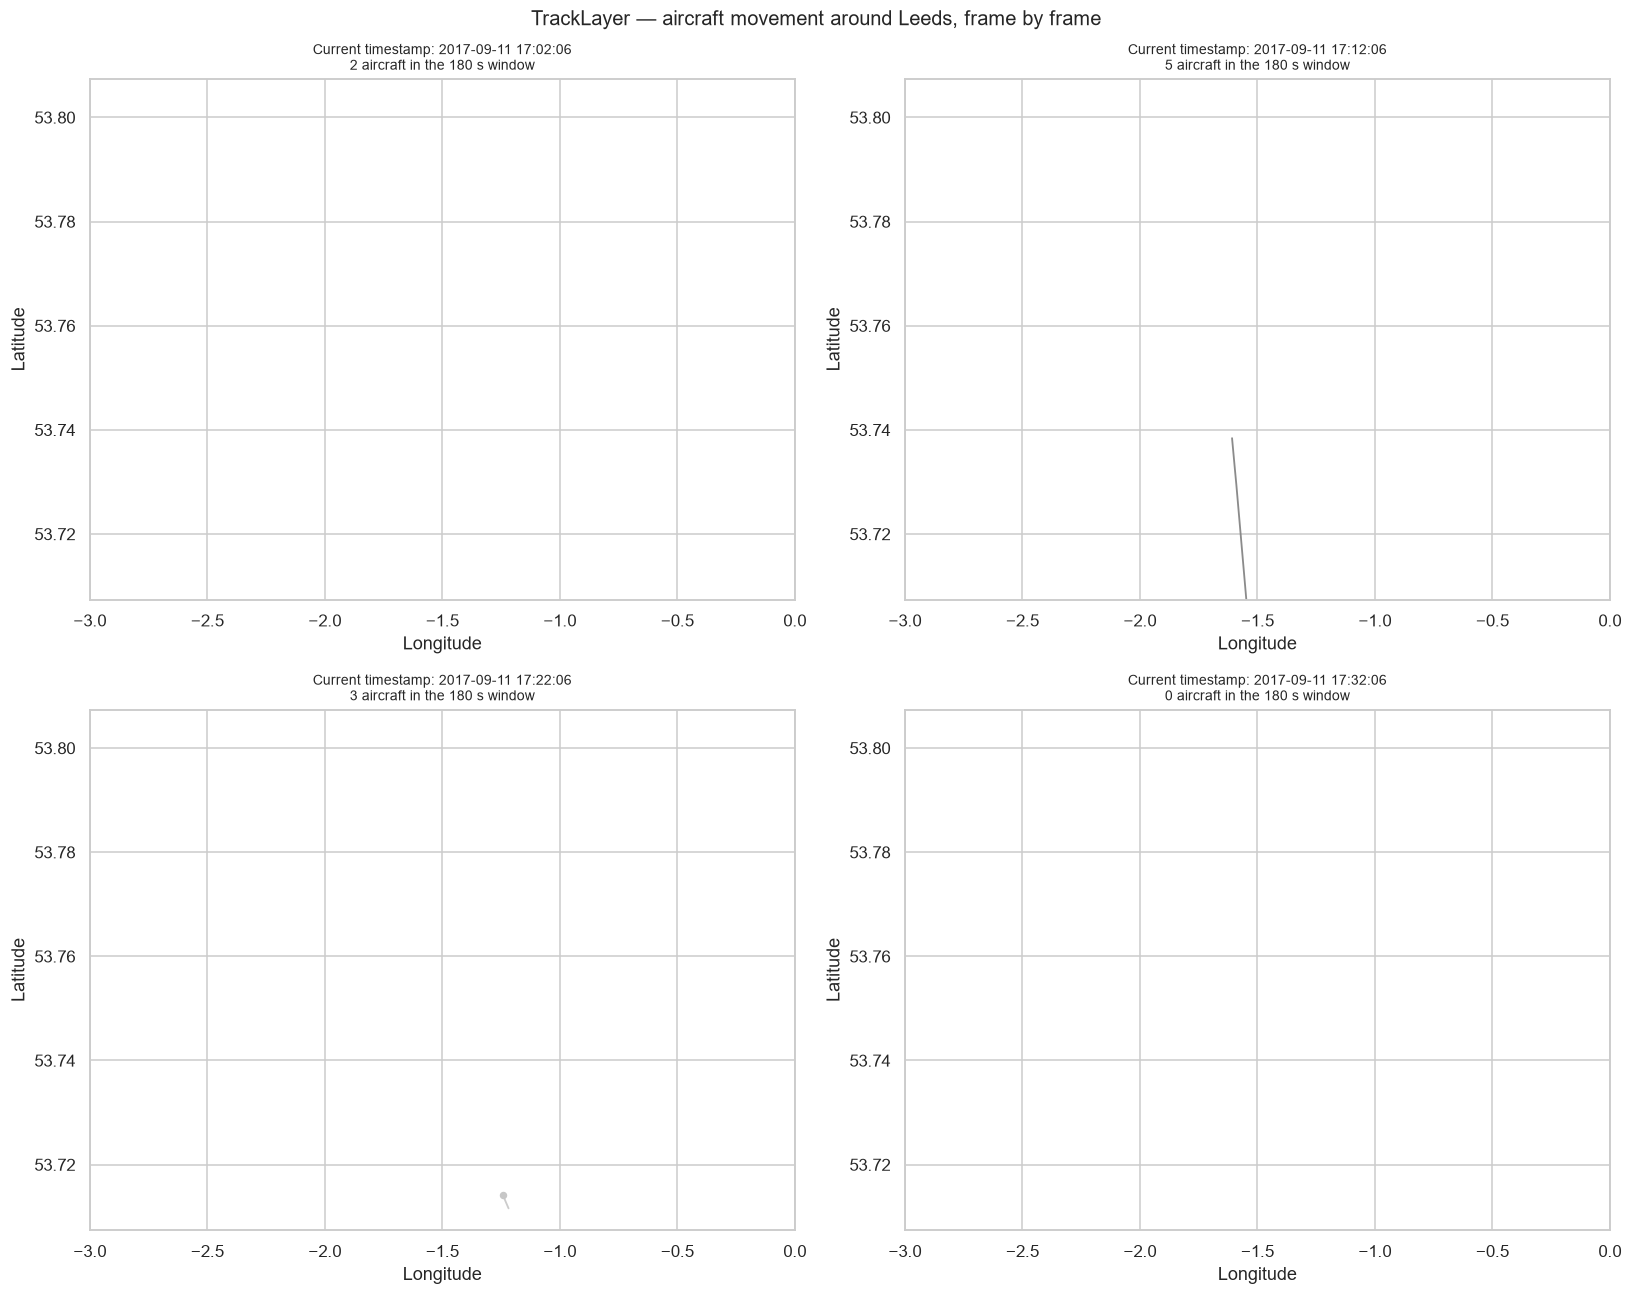

In [8]:
# Render the layer: draw several consecutive frames of the animation, i.e. what
# the live map would look like as `self.time` advances.
frame_starts = [dataset['timestamp'].min() + k * 600 for k in range(4)]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, t in zip(axes.ravel(), frame_starts):
    t = int(t)
    tracks = layer.frame(t)
    for ident, pts in tracks:
        ax.plot(pts[:, 0], pts[:, 1], color=layer.cmap[ident],
                linewidth=1.2, alpha=0.9)
        ax.scatter(pts[-1, 0], pts[-1, 1], color=layer.cmap[ident], s=15, zorder=3)
    ax.set_xlim(leeds_bbox['west'], leeds_bbox['east'])
    ax.set_ylim(leeds_bbox['south'], leeds_bbox['north'])
    ax.set_title('%s\n%d aircraft in the 180 s window'
                 % (layer.ui_info(t), len(tracks)), fontsize=9)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
fig.suptitle('TrackLayer — aircraft movement around Leeds, frame by frame',
             fontsize=13)
fig.tight_layout()
plt.show()

busiest aircraft: 400FF2 | callsign: <ArrowStringArray>
['TOM8VT  ']
Length: 1, dtype: str | positions: 564


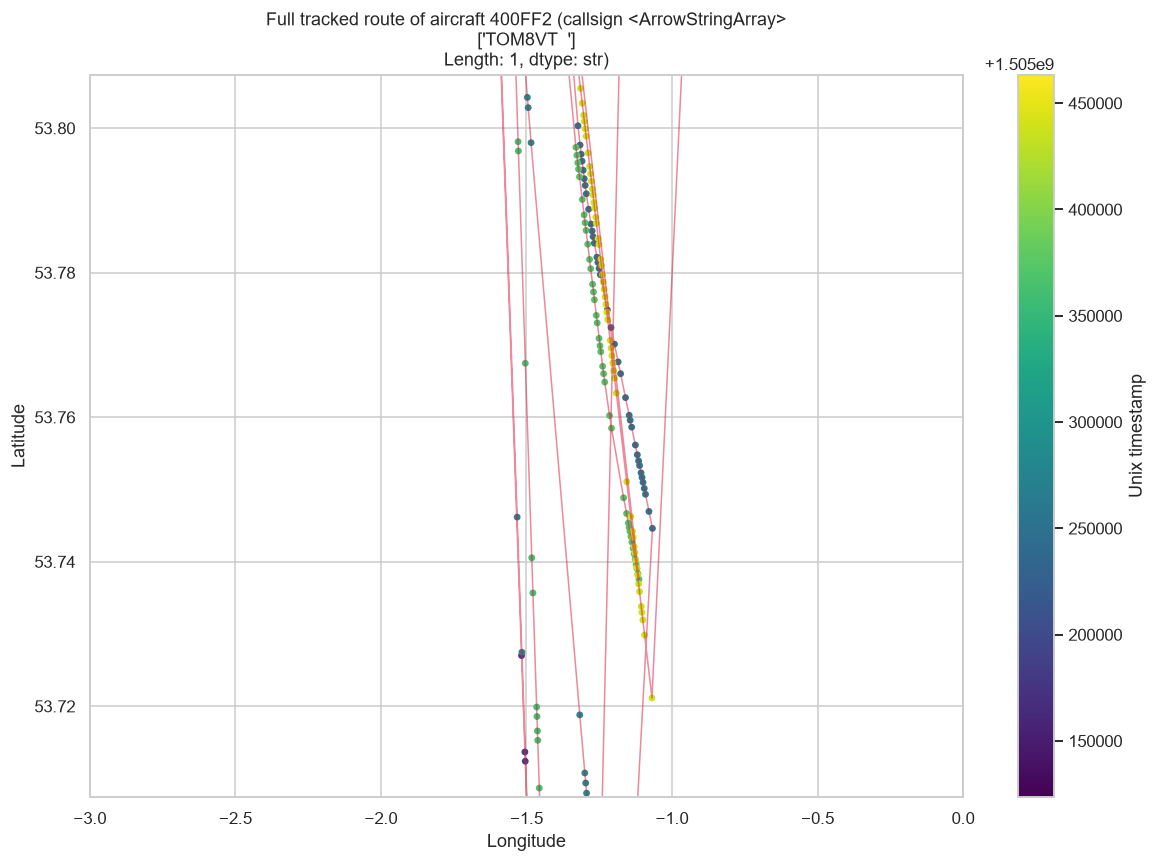

In [9]:
# The same layer for a single, larger window so one aircraft's full route is
# clearly visible — the "route of the aircraft" the exercise talks about.
target = dataset['hex_ident'].value_counts().idxmax()
plane = dataset[dataset['hex_ident'] == target].sort_values('timestamp')
print('busiest aircraft:', target, '| callsign:', plane['callsign'].dropna().unique()[:1],
      '| positions:', len(plane))

fig, ax = plt.subplots(figsize=(11, 8))
ax.plot(plane['lon'], plane['lat'], color='crimson', linewidth=1.0, alpha=0.5)
sc = ax.scatter(plane['lon'], plane['lat'], c=plane['timestamp'], cmap='viridis',
                s=12)
fig.colorbar(sc, ax=ax, label='Unix timestamp')
ax.set_xlim(leeds_bbox['west'], leeds_bbox['east'])
ax.set_ylim(leeds_bbox['south'], leeds_bbox['north'])
ax.set_title('Full tracked route of aircraft %s (callsign %s)'
             % (target, plane['callsign'].dropna().unique()[:1]))
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
fig.tight_layout()
plt.show()

**Mapping onto the tutorial's layer.** `__init__` keeps the data, a
`colorbrewer`-style per-aircraft colour map, the starting `self.time` and the
view bounds. The `draw` step filters `timestamp > self.time and
<= self.time + 180`, paints each aircraft's points, then does `self.time += 1`
and wraps back to the minimum once it passes the maximum. `ui_manager.info(...)`
is the per-frame title `Current timestamp: ...`, and `bbox()` is `leeds_bbox`.
`BatchPainter.set_color` becomes the per-aircraft line colour, and
`painter.points(x, y, 15, rounded=True)` becomes the scattered position markers.

In [10]:
# Summary statistics quoted in the project README — every number below is
# computed here, so the README is reproducible from this notebook.
print('reports                :', len(dataset))
print('distinct hex_ident     :', dataset['hex_ident'].nunique())
print('distinct callsigns     :', dataset['callsign'].nunique())
counts = dataset['hex_ident'].value_counts()
print('reports per aircraft   : min %d, median %d, mean %.1f, max %d'
      % (counts.min(), counts.median(), counts.mean(), counts.max()))
print('aircraft with >=50 reports :', int((counts >= 50).sum()))
print('aircraft with >=100 reports:', int((counts >= 100).sum()))
print('rows per day:')
print(dataset['date'].value_counts().sort_index().to_string())
print()
print('altitude(feet)         : min %d, max %d, mean %.0f'
      % (dataset['altitude(feet)'].min(), dataset['altitude(feet)'].max(),
         dataset['altitude(feet)'].mean()))
print('ground_speed(knotph)   : min %.0f, max %.0f, mean %.0f'
      % (dataset['ground_speed(knotph)'].min(),
         dataset['ground_speed(knotph)'].max(),
         dataset['ground_speed(knotph)'].mean()))
print()
bands = pd.cut(dataset['altitude(feet)'],
               bins=[-1, 1000, 5000, 10000, 20000, 50000],
               labels=['0-1k', '1-5k', '5-10k', '10-20k', '20k+'])
band_counts = bands.value_counts().sort_index()
band_share = (band_counts / len(dataset) * 100).round(1)
print('altitude band distribution:')
for band in band_counts.index:
    print('   %-8s %6d reports  %5.1f%%' % (band, band_counts[band], band_share[band]))

reports                : 33766
distinct hex_ident     : 805
distinct callsigns     : 699
reports per aircraft   : min 1, median 18, mean 41.9, max 564
aircraft with >=50 reports : 197
aircraft with >=100 reports: 91
rows per day:
date
2017/09/11    1961
2017/09/12    6772
2017/09/13    7166
2017/09/14    7970
2017/09/15    8644
2017/09/16    1253

altitude(feet)         : min 2325, max 44975, mean 25983
ground_speed(knotph)   : min 85, max 611, mean 382

altitude band distribution:
   0-1k          0 reports    0.0%
   1-5k       3566 reports   10.6%
   5-10k       799 reports    2.4%
   10-20k     4803 reports   14.2%
   20k+      24598 reports   72.8%


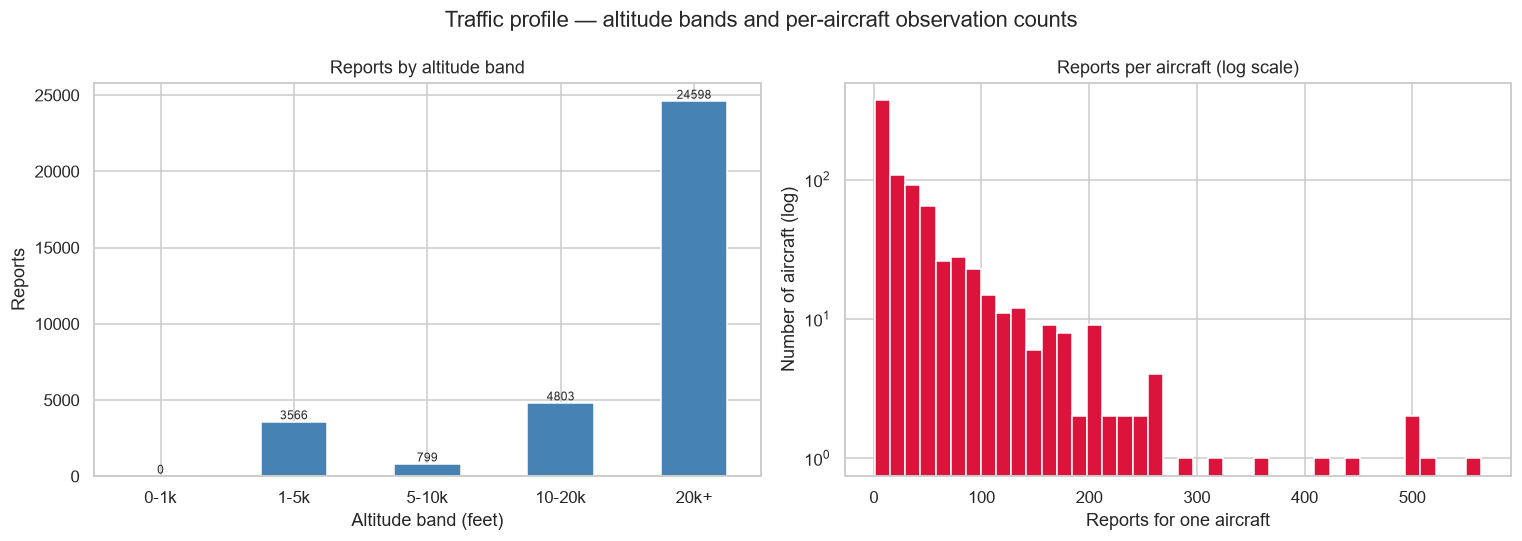

In [11]:
# Altitude distribution by band, and the reports-per-aircraft skew — the two
# findings the README reports.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

band_counts.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Reports by altitude band')
axes[0].set_xlabel('Altitude band (feet)')
axes[0].set_ylabel('Reports')
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(band_counts.values):
    axes[0].text(i, v, str(v), ha='center', va='bottom', fontsize=8)

axes[1].hist(counts.values, bins=40, color='crimson')
axes[1].set_yscale('log')
axes[1].set_title('Reports per aircraft (log scale)')
axes[1].set_xlabel('Reports for one aircraft')
axes[1].set_ylabel('Number of aircraft (log)')
fig.suptitle('Traffic profile — altitude bands and per-aircraft observation counts')
fig.tight_layout()
plt.show()

### Save

Submitted as **`MC652428_Exercise8.04.ipynb`**.